# 3 – Kök Bulma: Günün enerjisinin yarısı saat kaçta üretildi?

$E(t)$: sabah 04:00'ten $t$ anına kadar santralin ürettiği enerji. Aradığımız an, şu denklemin köküdür:
$$F(t) = E(t) - \tfrac12 E_{\text{gün}} = 0$$
Açık bir günde kök öğlen civarında olmalı; sabah bulutluysa daha geç, öğleden sonra bulutluysa daha erken.

Güzel bir detay: $F'(t) = P(t)$. Yani **Newton yönteminin ihtiyaç duyduğu türev, ölçtüğümüz güçtür.**

Kütüphaneleri yüklüyoruz. CSV dosyaları defterle aynı klasörde ya da `../data` klasöründe olabilir.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

VERI = Path(".") if Path("Plant_1_Generation_Data.csv").exists() else Path("../data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
saat_dk = lambda t: f"{int(t):02d}:{int(round(t % 1 * 60)):02d}"   # 12.5 -> "12:30"

## 1. Yöntemler

* **Bisection:** İşaret değiştiren $[a, b]$ aralığını her adımda ikiye böler. Her zaman yakınsar, ama yavaştır.
* **Newton:** Teğet doğrunun sıfırını yeni tahmin olarak alır: $x_{k+1} = x_k - F(x_k)/F'(x_k)$.
* **Secant:** Newton gibi, ama türev yerine son iki noktadan geçen doğrunun eğimini kullanır.

Her fonksiyon kökü ve her iterasyondaki tahminlerin listesini döndürüyor.

In [2]:
def bisection(f, a, b, tol=1e-10, maks=200):
    if f(a) * f(b) > 0:
        raise ValueError("f(a) ve f(b) aynı işaretli")
    tahminler = []
    for _ in range(maks):
        m = (a + b) / 2
        tahminler.append(m)
        if (b - a) / 2 < tol:
            break
        if f(a) * f(m) <= 0:
            b = m
        else:
            a = m
    return m, tahminler


def newton(f, df, x0, tol=1e-10, maks=50):
    x, tahminler = x0, []
    for _ in range(maks):
        egim = df(x)
        if egim == 0:
            raise ZeroDivisionError(f"x = {x}: türev sıfır, teğet yatay")
        adim = f(x) / egim
        x = x - adim
        tahminler.append(x)
        if abs(adim) < tol:
            break
    return x, tahminler


def secant(f, x0, x1, tol=1e-10, maks=50):
    tahminler = []
    for _ in range(maks):
        x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))
        tahminler.append(x2)
        if abs(x2 - x1) < tol:
            break
        x0, x1 = x1, x2
    return x2, tahminler

## 2. Basit test: $x^3 - 2 = 0$, kök $\sqrt[3]{2} \approx 1{,}259921$

In [3]:
f = lambda x: x**3 - 2
df = lambda x: 3 * x**2
for ad, (kok, tahmin) in [("Bisection [1, 2]", bisection(f, 1, 2)),
                          ("Newton (x0 = 1)", newton(f, df, 1.0)),
                          ("Secant (1, 2)", secant(f, 1.0, 2.0))]:
    print(f"{ad:17s} kök = {kok:.12f}   iterasyon = {len(tahmin):2d}   hata = {abs(kok - 2 ** (1 / 3)):.1e}")

Bisection [1, 2]  kök = 1.259921049874   iterasyon = 34   hata = 2.1e-11
Newton (x0 = 1)   kök = 1.259921049895   iterasyon =  6   hata = 0.0e+00
Secant (1, 2)     kök = 1.259921049895   iterasyon =  8   hata = 0.0e+00


Üçü de aynı kökü buluyor. Bisection 34 iterasyon, Newton 6, secant 8: Newton en hızlısı, bisection en yavaşı.

## 3. Veri: santralin günlük enerji eğrisi

Her zaman damgasında 22 inverterin gücünü topluyoruz. 04:00–20:00 arasındaki 65 noktanın hepsinde 22 inverterin hepsi ölçülmüş olan günleri tutuyoruz.

In [4]:
uretim = pd.read_csv(VERI / "Plant_1_Generation_Data.csv")
uretim["DATE_TIME"] = pd.to_datetime(uretim["DATE_TIME"], format="%d-%m-%Y %H:%M")
uretim["tarih"] = uretim["DATE_TIME"].dt.date
uretim["saat"] = uretim["DATE_TIME"].dt.hour + uretim["DATE_TIME"].dt.minute / 60
pencere = uretim[(uretim["saat"] >= 4) & (uretim["saat"] <= 20)]

santral = pencere.groupby(["tarih", "saat"]).agg(P=("AC_POWER", "sum"), n=("AC_POWER", "size")).reset_index()
gunler = {}                                   # tarih -> santral gücü (65 nokta, kW)
for tarih, g in santral.groupby("tarih"):
    if len(g) == 65 and (g["n"] == 22).all():
        gunler[tarih] = g["P"].to_numpy()
ts = np.linspace(4, 20, 65)                   # saat
h = 0.25
print("Tam veri olan gün sayısı:", len(gunler))

Tam veri olan gün sayısı: 17


**$E(t)$ nasıl hesaplanır?** Güç noktalarını düz çizgilerle birleştiriyoruz (`np.interp`). $E(t)$ bu çizgilerin altındaki alan:
ölçüm noktalarında birikimli trapez toplamı (Defter 1), iki ölçüm arasında ise tam olarak bir parabol:
$$E(t) = E_i + P_i\,\tau + \tfrac12\, m_i\,\tau^2, \qquad \tau = t - t_i,\quad m_i = \frac{P_{i+1} - P_i}{h}$$
Bu şekilde $F'(t) = P(t)$ eşitliği tam olarak sağlanıyor.

In [5]:
def enerji_fonksiyonlari(P):
    """Bir günün güç dizisinden F(t) ve F'(t) = P(t) fonksiyonlarını kurar."""
    E_nokta = np.concatenate([[0], np.cumsum(h * (P[1:] + P[:-1]) / 2)])   # birikimli trapez
    yarim = E_nokta[-1] / 2

    def F(t):
        i = min(max(int((t - 4) / h), 0), 63)          # t hangi aralıkta?
        tau = t - ts[i]
        m = (P[i + 1] - P[i]) / h
        return E_nokta[i] + P[i] * tau + 0.5 * m * tau**2 - yarim

    def dF(t):
        return np.interp(t, ts, P)

    return F, dF, E_nokta

Bir gün seçip güç eğrisini ve $F(t)$'yi çiziyoruz. $F$ sabah $-\tfrac12 E_\text{gün}$'den başlayıp akşam $+\tfrac12 E_\text{gün}$'e çıkıyor; sıfırı kestiği yer aradığımız kök.

Günlük enerji: 142.1 MWh


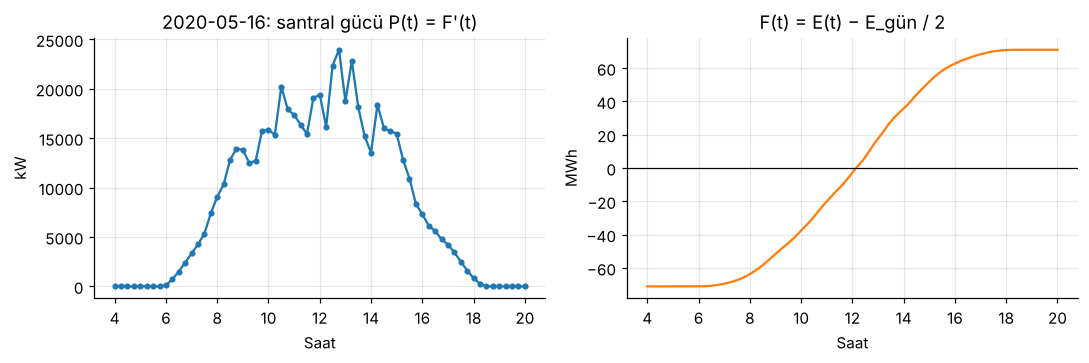

In [6]:
gun = list(gunler)[0]
P = gunler[gun]
F, dF, E_nokta = enerji_fonksiyonlari(P)
tt = np.linspace(4, 20, 641)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.plot(ts, P, "o-", ms=3)
ax1.set_title(f"{gun}: santral gücü P(t) = F'(t)"); ax1.set_ylabel("kW")
ax2.plot(tt, [F(t) / 1000 for t in tt], color="C1")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_title("F(t) = E(t) − E_gün / 2"); ax2.set_ylabel("MWh")
for ax in (ax1, ax2):
    ax.set_xlabel("Saat"); ax.set_xticks(range(4, 21, 2))
plt.tight_layout(); plt.show()
print(f"Günlük enerji: {E_nokta[-1] / 1000:.1f} MWh")

Kökü üç yöntemle buluyoruz: bisection $[8, 16]$ aralığından, Newton öğlenden (12:00), secant 11:00 ve 13:00'ten başlıyor.
Kontrol için SciPy'nin `brentq` fonksiyonunu da kullanıyoruz.

In [7]:
kok_B, tahmin_B = bisection(F, 8, 16)
kok_N, tahmin_N = newton(F, dF, 12.0)
kok_S, tahmin_S = secant(F, 11.0, 13.0)
kok_scipy = optimize.brentq(F, 8, 16, xtol=1e-14)

for ad, kok, tahmin in [("Bisection", kok_B, tahmin_B), ("Newton", kok_N, tahmin_N), ("Secant", kok_S, tahmin_S)]:
    print(f"{ad:9s}  kök = {kok:.10f} saat ({saat_dk(kok)})   iterasyon = {len(tahmin)}")
print(f"SciPy      kök = {kok_scipy:.10f} saat")

Bisection  kök = 12.1470918888 saat (12:09)   iterasyon = 37
Newton     kök = 12.1470918887 saat (12:09)   iterasyon = 5
Secant     kök = 12.1470918887 saat (12:09)   iterasyon = 7
SciPy      kök = 12.1470918887 saat


## 4. Hata iterasyonlarla nasıl azalıyor?

Her iterasyondaki $|x_k - \text{kök}|$ hatası (saat cinsinden). Kök olarak SciPy'nin sonucunu alıyoruz.

In [8]:
satir = 8
hata_tablosu = pd.DataFrame({
    "Bisection sınırı (b−a)/2^k": pd.Series(8 / 2.0 ** np.arange(1, satir + 1)),
    **{ad: pd.Series(np.abs(np.array(tahmin[:satir]) - kok_scipy))
    for ad, tahmin in [("Bisection", tahmin_B), ("Newton", tahmin_N), ("Secant", tahmin_S)]}
})
hata_tablosu.index = range(1, len(hata_tablosu) + 1)
hata_tablosu.index.name = "iterasyon"
hata_tablosu.map(lambda e: "" if pd.isna(e) else f"{e:.1e}")

,Bisection sınırı (b−a)/2^k,Bisection,Newton,Secant
iterasyon,,,,
1,4.0e+00,1.5e-01,7.3e-03,8.4e-02
2,2.0e+00,1.9e+00,2.0e-05,1.0e-02
3,1.0e+00,8.5e-01,1.4e-10,3.0e-04
4,5.0e-01,3.5e-01,0.0e+00,1.1e-06
5,2.5e-01,1.0e-01,0.0e+00,1.3e-10
6,1.2e-01,2.2e-02,,0.0e+00
7,6.2e-02,4.0e-02,,0.0e+00
8,3.1e-02,9.2e-03,,


* **Bisection:** Hatanın üst sınırı (aralığın yarı genişliği) her adımda tam olarak yarıya iniyor (lineer yakınsama, oran 1/2). Gerçek hata bu sınırın altında kalıyor ama tahmin kökün bir sağına bir soluna düştüğü için düzenli azalmıyor. $10^{-10}$ için $\log_2(8 / 10^{-10}) \approx 37$ adım gerekiyor.
* **Newton:** Doğru basamak sayısı her adımda kabaca ikiye katlanıyor (kuadratik yakınsama).
* **Secant:** İkisinin arasında (mertebe ≈ 1,618).

## 5. Kötü başlangıç: Newton'u gece başlatmak

05:00'te güç 0, yani $F'(t) = 0$. Teğet yatay olduğu için sıfırı kestiği bir nokta yok ve Newton sıfıra bölmeye düşüyor.

In [9]:
print(f"P(05:00) = {dF(5.0)} kW")
try:
    newton(F, dF, 5.0)
except ZeroDivisionError as hata:
    print("Newton başarısız:", hata)

P(05:00) = 0.0 kW
Newton başarısız: x = 5.0: türev sıfır, teğet yatay


Newton hızlıdır ama iyi bir başlangıç noktası ister. Bisection ise yavaştır ama işaret değiştiren bir aralık verildiği sürece her zaman yakınsar.

## 6. Bütün günler için yarı enerji saati

Her gün için kökü Newton'la (12:00'den başlayarak) buluyor ve bisection sonucuyla kontrol ediyoruz.

Medyan yarı enerji saati: 12:09
En erken / en geç       : 11:07 / 13:16
Newton iterasyon sayıları: {3: 1, 4: 6, 5: 8, 6: 2}


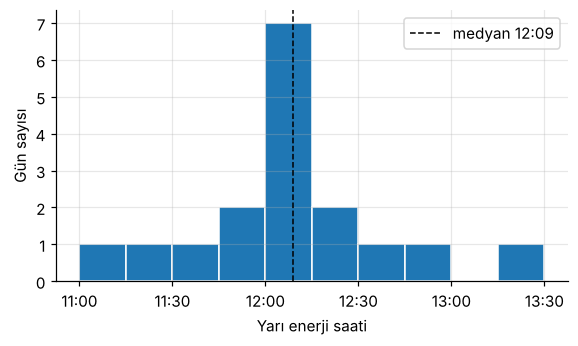

In [10]:
yari_saat, iterasyon = [], []
for tarih, P_gun in gunler.items():
    F_g, dF_g, _ = enerji_fonksiyonlari(P_gun)
    kok, tahmin = newton(F_g, dF_g, 12.0)
    assert abs(kok - bisection(F_g, 8, 16)[0]) < 1e-8
    yari_saat.append(kok)
    iterasyon.append(len(tahmin))
yari_saat = np.array(yari_saat)

print(f"Medyan yarı enerji saati: {saat_dk(np.median(yari_saat))}")
print(f"En erken / en geç       : {saat_dk(yari_saat.min())} / {saat_dk(yari_saat.max())}")
print("Newton iterasyon sayıları:", pd.Series(iterasyon).value_counts().sort_index().to_dict())

plt.figure(figsize=(6, 3.2))
plt.hist(yari_saat, bins=np.arange(11, 13.6, 0.25), edgecolor="white")
plt.axvline(np.median(yari_saat), color="k", ls="--", lw=1, label=f"medyan {saat_dk(np.median(yari_saat))}")
plt.xticks(np.arange(11, 13.6, 0.5), [saat_dk(x) for x in np.arange(11, 13.6, 0.5)])
plt.xlabel("Yarı enerji saati"); plt.ylabel("Gün sayısı")
plt.legend(); plt.show()

## Sonuç

* Günün enerjisinin yarısı medyan olarak **≈ 12:09**'da üretilmiş oluyor; 17 gün içinde 11:07 ile 13:16 arasında değişiyor. Saatin öğlenden sapması, bulutların günün hangi yarısında geldiğini gösteriyor.
* Bisection $[8, 16]$ aralığından başlayınca $10^{-10}$ hassasiyet için **37 iterasyon**, Newton öğlenden başlayınca sadece **4–5 iterasyon** gerekiyor (17 günün 14'ünde; tüm günlerde 3–6).
* Newton'un ihtiyaç duyduğu türev ayrıca hesaplanmadı: $F'(t) = P(t)$, yani ölçülen güç.
* Newton'u gece başlatınca türev (güç) sıfır olduğu için yöntem çöküyor. Hızlı yöntemler iyi bir başlangıç noktası ister; bisection ise yavaş ama garantili.